# Assignment 2 — Data Preparation & Baseline

**Проект:** lawrag — офлайн-система вопросно-ответного поиска по кодексам Республики Казахстан (RU + KK).
Продолжение Assignment 1 (Project Proposal).

Ноутбук выполняется последовательно `Restart → Run All` без ручной правки путей: он сам находит корень репозитория
(локально) или клонирует его (Google Colab). Полный прогон — около 4–6 минут на ноутбуке (разбор 85 МБ HTML занимает ~70 с,
вычисление baseline — ~1–2 мин).

| № | Шаг задания | Раздел |
|---|---|---|
| 1 | загрузить датасет | §2 |
| 2 | изучить структуру | §3 |
| 3 | определить размер | §3.4 |
| 4 | проверить пропуски | §4.1 |
| 5 | проверить дубликаты | §4.2 |
| 6 | провести очистку | §5 |
| 7 | выполнить EDA | §6 |
| 8 | визуализировать основные характеристики | §6, §8, §9 (9 графиков) |
| 9 | определить признаки и target | §7 |
| 10 | разделить на train / validation / test | §8 |
| — | baseline | §9 |

## 1. Датасет и исследовательская постановка

### 1.1 Выбор и описание датасета

| Параметр | Значение |
|---|---|
| **Первоисточник** | [adilet.zan.kz](https://adilet.zan.kz) — Эталонный контрольный банк НПА РК, официальный канал публикации текстов кодексов (Институт законодательства и правовой информации РК, Министерство юстиции РК) |
| **Предметная область** | законодательство Республики Казахстан: 20 кодексов + редакция Налогового кодекса 2017 г. |
| **Происхождение** | HTML-страницы актуальных редакций, загруженные модулем `src/lawrag/ingest/fetch_adilet.py`; ссылка на каждую страницу хранится в `data/adilet/documents.json` |
| **Период сбора** | снимок от **08.09.2026** (`fetched_at` в `documents.json`). Тексты охватывают нормы, принятые с 1994 г. (Гражданский кодекс) по 2026 г. |
| **Языки** | русский и казахский (оба официальных; Гражданский процессуальный кодекс в снимке есть только на русском) |
| **Назначение** | корпус для RAG-системы: поиск нормы по вопросу на естественном языке, дословное цитирование с датой редакции |

**Почему датасет подходит для задачи.** Основная AI-задача проекта — информационный поиск (ранжирование фрагментов
закона по вопросу). Для неё нужен (а) полный текст норм с их структурой (кодекс → глава → статья → пункт), (б) даты
действия редакций и (в) оба языка. Официальный первоисточник даёт все три; любые вторичные пересказы законов
непригодны, потому что ответ системы должен быть дословной цитатой.

**Единицы анализа.** Сырой HTML превращается в три таблицы:

* `articles` — одна строка на статью в одном языке (структурная единица закона);
* `chunks` — индексируемые фрагменты (статья целиком или пункт большой статьи) — то, что ранжирует поисковик;
* `pairs` — обучающие/оценочные пары *(запрос → статья)*, добытые из самого корпуса (размеченного набора для
  казахстанского права не существует, см. Assignment 1, §6).

### 1.2 Исследовательская постановка

**Проблема.** Пользователь без юридического образования формулирует вопрос своими словами, часто на казахском,
а ответом должна быть конкретная статья. Нужно понять, насколько эта задача решается простым лексическим поиском и
где он ломается, — это определяет, оправдана ли доменная адаптация эмбеддера (Задача 3 проекта).

**Цель этапа.** Подготовить чистый, воспроизводимый набор данных *(запрос → статья)* с разбиением без утечки
и измерить на нём лексический baseline, относительно которого будут сравниваться плотный и гибридный поиск.

**Исследовательские вопросы:**

* **RQ1.** Какую долю запросов лексический поиск (TF-IDF) находит в топ-10 и как это зависит от *типа* запроса
  (заголовок, предложение с вырезанной ссылкой, определение, межъязыковой)?
* **RQ2.** Отличается ли казахская часть корпуса от русской по объёму, структуре и лексической находимости настолько,
  чтобы требовать отдельной обработки?
* **RQ3.** Насколько корпус неоднороден во времени (даты начала действия текущих редакций статей), то есть
  оправдана ли фильтрация «по состоянию на дату» в каждой ветке поиска?

**Гипотезы:**

* **H1.** Лексический baseline даёт высокий recall@10 на запросах-заголовках (их слова буквально есть в статье),
  но recall@10 < 0,5 на запросах с вырезанной ссылкой и около нуля на межъязыковых запросах.
* **H2.** На казахских запросах лексический baseline хуже, чем на русских (агглютинативная морфология дробит
  словоформы).
* **H3.** Более половины статей имеют текущую редакцию, вступившую в силу позже даты принятия кодекса, т. е.
  дата «по состоянию на» реально меняет ответ.

## 0. Окружение и константы

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/YelyelyeL2023/lawrag.git"
COLAB_CLONE_DIR = Path("/content/lawrag")
REPO_MARKER = Path("src") / "lawrag" / "__init__.py"


def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / REPO_MARKER).exists():
            return candidate
    if "google.colab" in sys.modules:
        if not COLAB_CLONE_DIR.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(COLAB_CLONE_DIR)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydantic", "pyyaml", "beautifulsoup4", "lxml"],
                       check=True)
        return COLAB_CLONE_DIR
    raise FileNotFoundError("Не найден корень репозитория lawrag: запустите ноутбук внутри клона репозитория.")


REPO_ROOT = find_repo_root()
sys.path.insert(0, str(REPO_ROOT / "src"))
DATA_DIR = REPO_ROOT / "data" / "adilet"
print("repo:", REPO_ROOT)
print("data:", DATA_DIR)

repo: /Users/baltabaev/PycharmProjects/lawrag
data: /Users/baltabaev/PycharmProjects/lawrag/data/adilet


In [2]:
import hashlib
import json
import logging
import re
import time
from collections import Counter
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold

from lawrag.config import ChunkConfig
from lawrag.ingest import refs as R
from lawrag.ingest import structure as S
from lawrag.ingest.parser import UNDATED
from lawrag.models import Lang, NodeKind, OPEN_ENDED
from lawrag.train import pairs as P

SEED = 13
np.random.seed(SEED)

# Разбиение по статьям на 10 фолдов: 1 фолд test, 1 validation, 8 train (80 / 10 / 10)
N_FOLDS, TEST_FOLD, VAL_FOLD = 10, 0, 1
TOP_K = 10
QUERY_BATCH = 512
MAX_ARTICLE_TOKENS = ChunkConfig().max_article_tokens
PAIR_CAPS = P.DEFAULT_CAPS
SHORT_TEXT_CHARS = 200
# Редакционные пометки adilet о будущих поправках («предусматривается исключить Законом РК от …»)
EDITORIAL_NOTE_RE = re.compile(r"(вводится в действие с|қолданысқа енгізіледі|предусматрива\w+\s+(исключ|изменени))",
                               re.IGNORECASE)

LANG_COLORS = {"ru": "#2a78d6", "kk": "#eb6834"}
SINGLE_COLOR = "#2a78d6"
KIND_ORDER = ["heading", "xref", "definition", "xlang"]
KIND_LABELS = {"heading": "заголовок", "xref": "вырез. ссылка", "definition": "определение", "xlang": "межъязык."}

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

## 2. Загрузка датасета

Сначала читаем манифест `documents.json` и проверяем целостность сырых файлов (размер, SHA-256). Затем каждый HTML
разбирается *тем же* парсером, что использует индексатор проекта (`lawrag.ingest.parser.parse_adilet`), — так
анализируемые данные совпадают с тем, что попадает в поисковый индекс.

Предупреждения парсера не выводятся на экран, а собираются в список: их количество — одна из метрик качества данных (§4.3).

In [3]:
documents = pd.DataFrame(json.loads((DATA_DIR / "documents.json").read_text(encoding="utf-8")))


def file_digest(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]


documents["exists"] = documents["file"].map(lambda f: (DATA_DIR / f).exists())
documents["size_mb"] = documents["file"].map(lambda f: (DATA_DIR / f).stat().st_size / 2**20)
documents["sha256"] = documents["file"].map(lambda f: file_digest(DATA_DIR / f))
documents["fetched_at"] = pd.to_datetime(documents["fetched_at"])
print(f"Документов: {len(documents)}, все файлы на месте: {documents['exists'].all()}, "
      f"объём: {documents['size_mb'].sum():.1f} МБ")
documents[["file", "code", "lang", "official_id", "size_mb", "sha256", "title"]].head(8)

Документов: 41, все файлы на месте: True, объём: 85.0 МБ


,file,code,lang,official_id,size_mb,sha256,title
0,gk.ru.html,gk,ru,K940001000_,1.020276,cefc83889a60,Гражданский кодекс Республики Казахстан (Общая часть)
1,gk.kk.html,gk,kk,K940001000_,0.974046,832f0d4e0c4a,Қазақстан Республикасының Азаматтық кодексі (Жалпы бөлім)
2,gpk.ru.html,gpk,ru,K1500000377,1.374487,83fbf7883fdf,Гражданский процессуальный кодекс
3,uk.ru.html,uk,ru,K1400000226,1.840338,7553e655d35c,Уголовный кодекс Республики Казахстан
4,uk.kk.html,uk,kk,K1400000226,1.794210,e8664372ee54,Қазақстан Республикасының Қылмыстық кодексі
5,upk.ru.html,upk,ru,K1400000231,2.834205,0487827dab11,Уголовно-процессуальный кодекс
6,upk.kk.html,upk,kk,K1400000231,2.762895,69e08807c709,Қылмыстық-процестік кодекс
7,uik.ru.html,uik,ru,K1400000234,0.715230,e7942bdd6b68,Уголовно-исполнительный кодекс


In [4]:
class ParserWarnings(logging.Handler):
    def __init__(self):
        super().__init__(level=logging.WARNING)
        self.messages = []

    def emit(self, record):
        self.messages.append(record.getMessage())


parser_warnings = ParserWarnings()
lawrag_logger = logging.getLogger("lawrag")
lawrag_logger.handlers = [parser_warnings]
lawrag_logger.propagate = False
lawrag_logger.setLevel(logging.WARNING)

started = time.time()
trees = P.load_trees(DATA_DIR)
corpus = P.build_corpus(trees, ChunkConfig())
print(f"Разобрано документов: {len(trees)}, фрагментов (chunks): {len(corpus.chunks):,}, "
      f"предупреждений парсера: {len(parser_warnings.messages):,}, время: {time.time() - started:.0f} с")

Разобрано документов: 41, фрагментов (chunks): 43,857, предупреждений парсера: 1,572, время: 72 с


## 3. Структура данных

### 3.1 Таблица статей (`articles`)

Обходим дерево каждого документа и собираем одну строку на статью. Даты храним сначала как объекты `date`
(в исходной модели так), приведение типов — часть очистки (§5.1).

In [5]:
def article_row(article, doc):
    text = article.texts.get(doc.lang)
    heading = text.heading if text else ""
    body = text.body if text else ""
    points = [c for c in article.children if c.kind is NodeKind.POINT]
    return {
        "act_code": doc.act_code,
        "lang": doc.lang.value,
        "article_id": article.id,
        "number": article.number,
        "heading": heading,
        "body": body,
        "body_chars": len(body),
        "tokens": S.estimate_tokens(f"{heading}\n{body}"),
        "n_points": len(points),
        "has_note": any(c.kind is NodeKind.NOTE for c in article.children),
        "has_table": S.contains_table(body),
        "repealed": S.is_repealed(body),
        "valid_from": text.valid_from if text else None,
        "valid_to": text.valid_to if text else None,
        "detected_lang": S.detect_lang(f"{heading}\n{body}").value,
    }


articles_raw = pd.DataFrame([article_row(a, doc) for root, doc in trees for a in root.articles()])
articles_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 17029 entries, 0 to 17028
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   act_code       17029 non-null  str   
 1   lang           17029 non-null  str   
 2   article_id     17029 non-null  str   
 3   number         17029 non-null  str   
 4   heading        17029 non-null  str   
 5   body           17029 non-null  str   
 6   body_chars     17029 non-null  int64 
 7   tokens         17029 non-null  int64 
 8   n_points       17029 non-null  int64 
 9   has_note       17029 non-null  bool  
 10  has_table      17029 non-null  bool  
 11  repealed       17029 non-null  bool  
 12  valid_from     17029 non-null  object
 13  valid_to       17029 non-null  object
 14  detected_lang  17029 non-null  str   
dtypes: bool(3), int64(3), object(2), str(7)
memory usage: 1.6+ MB


In [6]:
articles_raw.drop(columns=['body']).head()

,act_code,lang,article_id,number,heading,body_chars,tokens,n_points,has_note,has_table,repealed,valid_from,valid_to,detected_lang
0,gk,ru,gk/st1,1,"Отношения, регулируемые гражданским законодательством",1237,516,4,False,False,False,1994-12-27,9999-12-31,ru
1,gk,ru,gk/st2,2,Основные начала гражданского законодательства,977,409,3,True,False,False,2011-04-05,9999-12-31,ru
2,gk,ru,gk/st3,3,Гражданское законодательство Республики Казахстан,3315,1346,8,True,False,False,2026-07-01,9999-12-31,ru
3,gk,ru,gk/st4,4,Действие гражданского законодательства во времени,627,270,2,False,False,False,1994-12-27,9999-12-31,ru
4,gk,ru,gk/st5,5,Применение гражданского законодательства по аналогии,603,262,2,False,False,False,1994-12-27,9999-12-31,ru


**Содержательное описание столбцов `articles`:**

| Столбец | Тип | Смысл |
|---|---|---|
| `act_code` | категория (21 значение) | короткий код кодекса (`gk` — Гражданский, `nk` — Налоговый, `koap` — КоАП …) |
| `lang` | категория (`ru`/`kk`) | язык текста по манифесту |
| `article_id` | строка | структурный идентификатор `код/stНомер`; **общий для RU и KK** — на нём держится выравнивание языков |
| `number` | строка | номер статьи; бывает составным (`1-1`, `24-2`) — вставленные поправками статьи |
| `heading` | текст | заголовок статьи — краткая формулировка предмета регулирования |
| `body` | текст | текст статьи без заголовка и без сносок об изменениях |
| `body_chars`, `tokens` | целое | длина в символах и оценка числа токенов (≈2,5 символа/токен для кириллицы) |
| `n_points` | целое | число пунктов: признак структурированности статьи, определяет нарезку на chunks |
| `has_note`, `has_table` | bool | есть примечание (юридически значимо) / таблица ставок — такие фрагменты не разрезаются |
| `repealed` | bool | статья «утратила силу»/«исключена» — в индексе остаётся заглушка |
| `valid_from`, `valid_to` | дата | интервал действия текущей редакции; `9999-12-31` — «действует бессрочно» |
| `detected_lang` | категория | язык, определённый по казахским буквам (ә ғ қ ң ө ұ ү һ і) — для проверки согласованности категорий |

In [7]:
articles_raw[["body_chars", "tokens", "n_points"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1)

,body_chars,tokens,n_points
count,17029.0,17029.0,17029.0
mean,2072.6,857.2,3.6
std,3140.8,1258.1,3.8
min,0.0,1.0,0.0
25%,598.0,266.0,2.0
50%,1208.0,511.0,3.0
75%,2452.0,1009.0,5.0
95%,6556.2,2653.6,10.0
99%,13500.4,5440.4,16.7
max,120967.0,48393.0,101.0


In [8]:
articles_raw[["act_code", "lang", "detected_lang"]].describe()

,act_code,lang,detected_lang
count,17029,17029,17029
unique,21,2,2
top,koap,ru,ru
freq,2158,8753,8751


### 3.2 Таблица фрагментов (`chunks`)

Фрагмент — индексируемая единица. Короткая статья = один фрагмент; статья длиннее
`max_article_tokens` режется по пунктам (с сохранением вводной части статьи), таблицы не разрезаются.

In [9]:
chunks_raw = pd.DataFrame([{
    "chunk_id": c.id, "article_id": c.article_node_id, "node_id": c.node_id, "act_code": c.act_code,
    "lang": c.lang.value, "is_whole_article": c.node_id == c.article_node_id, "tokens": c.token_estimate,
    "repealed": c.repealed, "valid_from": c.valid_from, "display_text": c.display_text,
} for c in corpus.chunks.values()])
chunks_raw.info()
chunks_raw.drop(columns=["display_text"]).head()

<class 'pandas.DataFrame'>
RangeIndex: 43857 entries, 0 to 43856
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   chunk_id          43857 non-null  str   
 1   article_id        43857 non-null  str   
 2   node_id           43857 non-null  str   
 3   act_code          43857 non-null  str   
 4   lang              43857 non-null  str   
 5   is_whole_article  43857 non-null  bool  
 6   tokens            43857 non-null  int64 
 7   repealed          43857 non-null  bool  
 8   valid_from        43857 non-null  object
 9   display_text      43857 non-null  str   
dtypes: bool(2), int64(1), object(1), str(6)
memory usage: 2.8+ MB


,chunk_id,article_id,node_id,act_code,lang,is_whole_article,tokens,repealed,valid_from
0,gk/st1#ru@1994-12-27,gk/st1,gk/st1,gk,ru,True,520,False,1994-12-27
1,gk/st2#ru@2011-04-05,gk/st2,gk/st2,gk,ru,True,413,False,2011-04-05
2,gk/st3/p1#ru@2026-07-01,gk/st3,gk/st3/p1,gk,ru,False,188,False,2026-07-01
3,gk/st3/p2#ru@2026-07-01,gk/st3,gk/st3/p2,gk,ru,False,238,False,2026-07-01
4,gk/st3/p3#ru@2026-07-01,gk/st3,gk/st3/p3,gk,ru,False,307,False,2026-07-01


| Столбец | Смысл |
|---|---|
| `chunk_id` | `узел#язык@дата_начала_действия` — уникален для редакции |
| `article_id` / `node_id` | статья-владелец / конкретный узел (статья или пункт `.../pN`) |
| `is_whole_article` | фрагмент — вся статья (а не пункт) |
| `display_text` | дословный текст, который будет процитирован пользователю |

### 3.3 Таблица пар (`pairs`) — источник target

Пары *(запрос → фрагмент)* добываются из корпуса четырьмя офлайн-способами модуля `lawrag.train.pairs`
(генерация вопросов LLM и журнал запросов требуют модели/БД и в этот этап не входят):

* `heading` — заголовок статьи → статья;
* `xref` — предложение, ссылающееся на статью B, *с вырезанным номером* → статья B (ближе всего к реальным вопросам);
* `definition` — термин / «что означает термин …?» → статья с легальным определением;
* `xlang` — текст на одном языке → тот же фрагмент на другом языке.

Здесь берутся *сырые* пары — без дедупликации и балансировки: это делается в §5 с обоснованием.

In [10]:
raw_pairs = [*P.mine_headings(trees, corpus), *P.mine_xrefs(trees, corpus),
             *P.mine_xlang(corpus), *P.mine_definitions(trees, corpus)]
pairs_raw = pd.DataFrame([p.to_dict() for p in raw_pairs]).rename(columns={"pos": "target_chunk",
                                                                            "article": "target_article"})
pairs_raw.info()
pairs_raw.sample(6, random_state=SEED)

<class 'pandas.DataFrame'>
RangeIndex: 83265 entries, 0 to 83264
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   query           83265 non-null  str  
 1   target_chunk    83265 non-null  str  
 2   target_article  83265 non-null  str  
 3   lang            83265 non-null  str  
 4   pos_lang        83265 non-null  str  
 5   kind            83265 non-null  str  
dtypes: str(6)
memory usage: 3.8 MB


,query,target_chunk,target_article,lang,pos_lang,kind
1390,Заражение венерической болезнью,uk/st117#ru@2018-07-23,uk/st117,ru,ru,heading
22474,"8) нормы амортизации по каждой подгруппе, группе фиксированных активов с уче...",nk/st280/p1#ru@2025-07-18,nk/st280,ru,ru,xref
77768,243-бап. Міндетті әлеуметтік сақтандыруға жататын адамдар\nМіндетті әлеуметт...,sk/st243#ru@2026-01-01,sk/st243,kk,ru,xlang
34154,Зонами таможенного контроля являются места перемещения товаров через таможен...,tamk/st528-2/p1#ru@2017-12-26,tamk/st528-2,ru,ru,xref
36210,Электрондық сауда тауарларына қатысты кедендік бажды осы Кодекстің көрсетілг...,tamk/st199/p1#kk@2017-12-26,tamk/st199,kk,kk,xref
45295,пункт 10. При рассмотрении ходатайства об условно-досрочном освобождении от ...,uik/st162/p10#kk@2025-09-15,uik/st162,ru,kk,xlang


| Столбец | Роль | Смысл |
|---|---|---|
| `query` | **признак (X)** | текст запроса |
| `lang` | признак | язык запроса |
| `target_chunk` | вспомогательный | конкретный фрагмент-источник пары |
| `target_article` + `pos_lang` | **target (y)** | статья и язык, которые должен найти поиск |
| `kind` | мета-данные | способ получения пары; используется для стратификации и разбивки метрик, **не** как признак модели |

### 3.4 Размер датасета

In [11]:
size = pd.DataFrame({
    "строк": [len(documents), len(articles_raw), len(chunks_raw), len(pairs_raw)],
    "столбцов": [documents.shape[1], articles_raw.shape[1], chunks_raw.shape[1], pairs_raw.shape[1]],
    "память, МБ": [round(df.memory_usage(deep=True).sum() / 2**20, 1)
                   for df in (documents, articles_raw, chunks_raw, pairs_raw)],
}, index=["documents (HTML)", "articles", "chunks", "pairs (сырые)"])
print(f"Сырые данные: {documents['size_mb'].sum():.1f} МБ HTML; "
      f"чистый текст статей: {articles_raw['body_chars'].sum() / 1e6:.1f} млн символов, "
      f"≈{articles_raw['tokens'].sum() / 1e6:.1f} млн токенов; "
      f"кодексов: {articles_raw['act_code'].nunique()}")
size

Сырые данные: 85.0 МБ HTML; чистый текст статей: 35.3 млн символов, ≈14.6 млн токенов; кодексов: 21


,строк,столбцов,"память, МБ"
documents (HTML),41,11,0.0
articles,17029,15,77.8
chunks,43857,10,86.6
pairs (сырые),83265,6,92.0


## 4. Анализ качества данных

### 4.1 Пропуски

В текстовом корпусе пропуск — не только `NaN`, но и пустая строка, отсутствие даты (заглушка `1900-01-01`,
которую парсер ставит, если дату установить нельзя) и отсутствие парного текста на втором языке.

In [12]:
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    blanks = df.apply(lambda col: col.map(lambda v: isinstance(v, str) and not v.strip()).sum())
    return pd.DataFrame({"NaN/None": df.isna().sum(), "пустая строка": blanks}).query(
        "`NaN/None` > 0 or `пустая строка` > 0")


print("articles — явные пропуски:")
display(missing_report(articles_raw))
print("pairs — явные пропуски:")
display(missing_report(pairs_raw))

undated = articles_raw["valid_from"] == UNDATED
ru_ids = set(articles_raw.loc[articles_raw.lang == "ru", "article_id"])
kk_ids = set(articles_raw.loc[articles_raw.lang == "kk", "article_id"])
missing_kk = ru_ids - kk_ids
missing_kk_by_act = Counter(a.split("/")[0] for a in missing_kk)
missing_ru = kk_ids - ru_ids

hidden_missing = pd.DataFrame({
    "кол-во": [int(undated.sum()), len(missing_kk), len(missing_ru),
               int((articles_raw.heading.str.strip() == "").sum()),
               int((articles_raw.body.str.strip() == "").sum())],
}, index=["дата начала действия неизвестна (1900-01-01)", "статья RU без KK-версии", "статья KK без RU-версии",
          "пустой заголовок", "пустой текст статьи"])
hidden_missing["% от статей"] = (hidden_missing["кол-во"] / len(articles_raw) * 100).round(2)
display(hidden_missing)
print("RU-статьи без KK-версии по кодексам:", dict(missing_kk_by_act.most_common(8)))

articles — явные пропуски:


,NaN/None,пустая строка
heading,0,4
body,0,374


pairs — явные пропуски:


,NaN/None,пустая строка


,кол-во,% от статей
дата начала действия неизвестна (1900-01-01),0,0.00
статья RU без KK-версии,495,2.91
статья KK без RU-версии,18,0.11
пустой заголовок,4,0.02
пустой текст статьи,374,2.20


RU-статьи без KK-версии по кодексам: {'gpk': 490, 'uk': 2, 'gk': 1, 'koap': 1, 'kozn': 1}


### 4.2 Дубликаты

Проверяем дубликаты на трёх уровнях: идентификаторы статей, тексты фрагментов и пары.
Особо важен **неоднозначный target**: один и тот же запрос указывает на разные статьи — это шум разметки.

In [13]:
dup_article_ids = articles_raw.duplicated(["article_id", "lang"]).sum()
dup_chunk_ids = chunks_raw["chunk_id"].duplicated().sum()
nonrepealed_chunks = chunks_raw[~chunks_raw.repealed]
dup_chunk_text = nonrepealed_chunks.duplicated(["lang", "display_text"]).sum()
dup_pairs_exact = pairs_raw.duplicated(["query", "target_chunk"]).sum()


def normalise_query(q: str) -> str:
    return " ".join(q.lower().split())


pairs_raw["query_norm"] = pairs_raw["query"].map(normalise_query)
targets_per_query = pairs_raw.groupby("query_norm")["target_article"].nunique()
ambiguous_queries = targets_per_query[targets_per_query > 1]
ambiguous_rows = pairs_raw["query_norm"].isin(ambiguous_queries.index).sum()

duplicates = pd.DataFrame({"кол-во": [dup_article_ids, dup_chunk_ids, dup_chunk_text, dup_pairs_exact,
                                      len(ambiguous_queries), ambiguous_rows]},
                          index=["повтор (article_id, lang)", "повтор chunk_id",
                                 "одинаковый текст разных фрагментов (без заглушек)",
                                 "полные дубликаты пар (query, target_chunk)",
                                 "запросы с >1 целевой статьёй", "пары с такими запросами"])
duplicates["% от таблицы"] = [round(v / n * 100, 2) for v, n in zip(
    duplicates["кол-во"], [len(articles_raw), len(chunks_raw), len(nonrepealed_chunks), len(pairs_raw),
                           pairs_raw["query_norm"].nunique(), len(pairs_raw)])]
display(duplicates)
print("Самые частые неоднозначные запросы:")
display(pairs_raw[pairs_raw.query_norm.isin(ambiguous_queries.index)]
        .groupby(["query_norm", "kind"]).target_article.nunique().sort_values(ascending=False).head(8))

,кол-во,% от таблицы
"повтор (article_id, lang)",0,0.00
повтор chunk_id,0,0.00
одинаковый текст разных фрагментов (без заглушек),774,1.79
"полные дубликаты пар (query, target_chunk)",9181,11.03
запросы с >1 целевой статьёй,2347,3.32
пары с такими запросами,7088,8.51


Самые частые неоднозначные запросы:


query_norm                                                                                             kind   
общие положения                                                                                        heading    90
жалпы ережелер                                                                                         heading    89
салықтық кезең                                                                                         heading    43
налоговый период                                                                                       heading    43
алып тастау көзделген – қр 11.06.2026 № 306-viii (01.01.2027 бастап қолданысқа енгізіледі ) заңымен.   xref       35
предусматривается исключить законом рк от 11.06.2026 № 306-viii (вводится в действие с 01.01.2027).    xref       34
салық салу объектісі                                                                                   heading    30
в предусматриваются изменения законом рк от 11.06.2026 № 306-viii (вво

### 4.3 Некорректные значения, выбросы, несогласованные категории, неверные типы

In [14]:
DUPLICATE_POINT_RE = re.compile(r"^(\S+) \[(\w+)\]: point .* occurs twice")
articles_with_merged_points = {m.groups() for m in map(DUPLICATE_POINT_RE.match, parser_warnings.messages) if m}

snapshot_day = documents["fetched_at"].max().date()
dated = articles_raw.loc[~undated, "valid_from"]
lang_mismatch = (articles_raw.lang != articles_raw.detected_lang) & (articles_raw.body_chars >= SHORT_TEXT_CHARS)
q1, q3 = articles_raw.tokens.quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
number_pattern = re.compile(r"^\d+(-\d+)*$")


def is_editorial_query(query: str) -> bool:
    return S.is_amendment_line(query) or bool(EDITORIAL_NOTE_RE.search(query))


xref_pairs = pairs_raw[pairs_raw.kind == "xref"]
article_numbers = xref_pairs.target_article.str.split("/st").str[1]
number_left_in_query = [bool(re.search(rf"(?<![\d-]){re.escape(n)}(?![\d-])", q))
                        for q, n in zip(xref_pairs["query"], article_numbers)]

quality = pd.DataFrame({"кол-во": [
    len(articles_with_merged_points),
    int((dated > snapshot_day).sum()),
    int(articles_raw.repealed.sum()),
    int(lang_mismatch.sum()),
    int((articles_raw.tokens > iqr_upper).sum()),
    int((articles_raw.tokens > MAX_ARTICLE_TOKENS).sum()),
    int((~articles_raw.number.fillna("").str.match(number_pattern)).sum()),
    int(sum(number_left_in_query)),
    int(xref_pairs["query"].map(is_editorial_query).sum()),
]}, index=[
    "статьи с повтором номера пункта (парсер слил тексты)",
    "valid_from позже даты снимка (вступает в силу в будущем)",
    "статьи-заглушки «утратила силу/исключена»",
    "язык по манифесту ≠ язык по тексту (текст ≥ 200 симв.)",
    f"выбросы длины по IQR (> {iqr_upper:.0f} токенов)",
    f"статьи длиннее порога нарезки ({MAX_ARTICLE_TOKENS} токенов)",
    "номер статьи нестандартного формата",
    "xref-запрос всё ещё содержит номер целевой статьи",
    "xref-запрос — редакционная пометка adilet, а не текст нормы",
])
quality["% базы"] = [round(v / n * 100, 2) for v, n in zip(quality["кол-во"], [
    len(articles_raw)] * 7 + [len(xref_pairs)] * 2)]
display(quality)
print("Типы данных дат до очистки:", articles_raw[["valid_from", "valid_to"]].dtypes.to_dict(),
      "— это Python-объекты, а не datetime64; сортировка/агрегация по ним неэффективна.")
print(f"Предупреждений парсера всего: {len(parser_warnings.messages):,}. "
      "Примеры статей, где язык текста не совпал с манифестом:")
display(articles_raw.loc[lang_mismatch, ["article_id", "lang", "detected_lang", "heading"]].head(5))

,кол-во,% базы
статьи с повтором номера пункта (парсер слил тексты),110,0.65
valid_from позже даты снимка (вступает в силу в будущем),0,0.00
статьи-заглушки «утратила силу/исключена»,152,0.89
язык по манифесту ≠ язык по тексту (текст ≥ 200 симв.),33,0.19
выбросы длины по IQR (> 2124 токенов),1336,7.85
статьи длиннее порога нарезки (1000 токенов),4300,25.25
номер статьи нестандартного формата,0,0.00
xref-запрос всё ещё содержит номер целевой статьи,183,0.81
"xref-запрос — редакционная пометка adilet, а не текст нормы",457,2.01


Типы данных дат до очистки: {'valid_from': dtype('O'), 'valid_to': dtype('O')} — это Python-объекты, а не datetime64; сортировка/агрегация по ним неэффективна.
Предупреждений парсера всего: 1,572. Примеры статей, где язык текста не совпал с манифестом:


,article_id,lang,detected_lang,heading
4268,koap/st177,ru,kk,Нарушение законодательства Республики Казахстан о реабилитации и банкротстве...
4271,koap/st180,ru,kk,Нарушение законодательства Республики Казахстан о реабилитации и банкротстве...
4272,koap/st181,ru,kk,Нарушение законодательства Республики Казахстан о реабилитации и банкротстве...
4314,koap/st213,ru,kk,Нарушение требований банковского законодательства Республики Казахстан
4766,koap/st608,ru,kk,"Управление транспортным средством водителем, находящимся в состоянии алкогол..."


**Количественный итог качества данных.**

* Явных `NaN` практически нет — парсер заполняет все поля; «скрытые» пропуски — даты-заглушки и отсутствие
  парного языка — видны только в доменных проверках выше.
* Дубликаты идентификаторов отсутствуют (уникальность `article_id`, `chunk_id` гарантирована структурой).
  Дублирующиеся *тексты* фрагментов — в основном стандартные формулировки, повторяющиеся в разных кодексах.
* Главный дефект разметки — **неоднозначные запросы**: одинаковые заголовки («Основные понятия, используемые
  в настоящем Кодексе», «Цели и задачи …») встречаются во многих кодексах, и пара «заголовок → статья» в таком
  случае не имеет единственного правильного ответа.
* Дат позже даты снимка нет: парсер намеренно игнорирует ещё не вступившие поправки
  (`lawrag.ingest.dating.latest_effective(..., not_after=снимок)`), а adilet показывает их лишь редакционными
  пометками. Эти пометки, однако, просачиваются в xref-запросы и удаляются при очистке (§5.3).
* Менее 1 % статей содержат повторяющиеся номера пунктов (парсер сливает их тексты); объём дефекта зафиксирован,
  исправление — задача парсера, а не очистки данных.
* Расхождение «язык по манифесту ≠ язык по тексту» — ложные срабатывания детектора: русские статьи КоАП,
  цитирующие казахские названия, набирают ≥ 3 казахских буквы. Манифест надёжнее, категория `lang` не меняется.
* Выбросы по длине — не ошибки, а реальные длинные статьи (определения, таблицы ставок). Удалять их нельзя:
  это законный текст; вместо этого они режутся по пунктам на этапе chunking.

## 5. Очистка данных

Каждое изменение обосновано; после каждого шага печатается состояние «до → после».

### 5.1 Типы данных и заглушки (articles, chunks)

In [15]:
def to_datetime_or_nat(series: pd.Series, sentinels: set) -> pd.Series:
    return pd.to_datetime(series.map(lambda d: None if d in sentinels else d))


articles = articles_raw.copy()
articles["is_current"] = articles["valid_to"] == OPEN_ENDED
articles["valid_from"] = to_datetime_or_nat(articles["valid_from"], {UNDATED})
articles["valid_to"] = to_datetime_or_nat(articles["valid_to"], {OPEN_ENDED})
for col in ("act_code", "lang", "detected_lang"):
    articles[col] = articles[col].astype("category")

chunks = chunks_raw.copy()
chunks["valid_from"] = to_datetime_or_nat(chunks["valid_from"], {UNDATED})
for col in ("act_code", "lang"):
    chunks[col] = chunks[col].astype("category")

print("dtypes до:", articles_raw[["valid_from", "act_code"]].dtypes.astype(str).to_dict())
print("dtypes после:", articles[["valid_from", "act_code"]].dtypes.astype(str).to_dict())
print(f"Память articles: {articles_raw.memory_usage(deep=True).sum() / 2**20:.1f} → "
      f"{articles.memory_usage(deep=True).sum() / 2**20:.1f} МБ")

dtypes до: {'valid_from': 'object', 'act_code': 'str'}
dtypes после: {'valid_from': 'datetime64[s]', 'act_code': 'category'}
Память articles: 79.9 → 76.4 МБ


*Обоснование.* Дата `1900-01-01` — техническая заглушка «дата неизвестна», а `9999-12-31` — «действует бессрочно».
Если оставить их числами, среднее и гистограммы дат сдвинутся на столетия; поэтому они заменены на `NaT`, а смысл
«бессрочно» сохранён в отдельном флаге `is_current`. Категориальные столбцы переведены в `category` (меньше памяти,
корректный порядок в группировках).

### 5.2 Статьи-заглушки

Статьи «утратила силу / исключена» **остаются в поисковом индексе** (пользователи спрашивают и об отменённых нормах,
и система обязана ответить «статья исключена»), но исключаются из анализа длины текста — заглушка в одну строку
искажает распределение длины действующих норм. Целевыми статьями пар они уже не являются: майнеры
`lawrag.train.pairs` их пропускают.

In [16]:
articles_text = articles[~articles.repealed]
print(f"Статьи для анализа текста: {len(articles):,} → {len(articles_text):,} "
      f"(убрано заглушек: {articles.repealed.sum():,})")
print(f"Медиана длины: {articles.tokens.median():.0f} → {articles_text.tokens.median():.0f} токенов")

Статьи для анализа текста: 17,029 → 16,877 (убрано заглушек: 152)
Медиана длины: 511 → 510 токенов


### 5.3 Очистка пар (target)

In [17]:
cleaning_log = []


def log_step(name: str, before: pd.DataFrame, after: pd.DataFrame, reason: str) -> pd.DataFrame:
    cleaning_log.append({"шаг": name, "до": len(before), "после": len(after),
                         "удалено": len(before) - len(after), "обоснование": reason})
    return after


pairs_step = pairs_raw.copy()

pairs_step = log_step(
    "1. Полные дубликаты (query, target_chunk)", pairs_step,
    pairs_step.drop_duplicates(["query", "target_chunk"]),
    "Повтор одного и того же примера завышает его вес в обучении и в метриках; одно и то же предложение со ссылкой "
    "встречается в нескольких пунктах.")

ambiguous = pairs_step.groupby("query_norm")["target_article"].transform("nunique") > 1
pairs_step = log_step(
    "2. Неоднозначные запросы (1 запрос → >1 статьи)", pairs_step, pairs_step[~ambiguous],
    "У запроса нет единственного правильного ответа (типовые заголовки «Основные понятия…» в разных кодексах). "
    "В метрике recall такие пары засчитали бы систему виноватой за верный, но «другой» ответ.")

xref_mask = pairs_step.kind == "xref"
xref_numbers = pairs_step.loc[xref_mask, "target_article"].str.split("/st").str[1]
leaky = pd.Series(False, index=pairs_step.index)
leaky.loc[xref_mask] = [bool(re.search(rf"(?<![\d-]){re.escape(n)}(?![\d-])", q))
                        for q, n in zip(pairs_step.loc[xref_mask, "query"], xref_numbers)]
pairs_step = log_step(
    "3. xref-запросы, где остался номер целевой статьи", pairs_step, pairs_step[~leaky],
    "Утечка target в признак: номер статьи должен быть вырезан, иначе модель учится сопоставлять цифры, а не смысл.")

editorial = (pairs_step.kind == "xref") & pairs_step["query"].map(is_editorial_query)
pairs_step = log_step(
    "4. xref-запросы — редакционные пометки adilet", pairs_step, pairs_step[~editorial],
    "Строка «предусматривается исключить Законом РК от …» — служебная пометка сайта о будущей поправке, "
    "а не текст нормы; как запрос она не несёт смысла статьи.")

before_cap = pairs_step
pairs_step = P.cap_per_kind([P.Pair(r.query, r.target_chunk, r.target_article, r.lang, r.pos_lang, r.kind)
                             for r in pairs_step.itertuples()], PAIR_CAPS, seed=SEED)
pairs_step = pd.DataFrame([p.to_dict() for p in pairs_step]).rename(
    columns={"pos": "target_chunk", "article": "target_article"})
pairs_step = log_step(
    f"5. Балансировка: не более {PAIR_CAPS} пар на тип", before_cap, pairs_step,
    "Межъязыковых пар ~40 тыс.; без ограничения они составили бы >50 % данных и заглушили бы xref-пары, "
    "наиболее похожие на реальные вопросы (тот же порог использует обучение эмбеддера проекта).")

pairs = pairs_step.reset_index(drop=True)
pairs["query_chars"] = pairs["query"].str.len()
pairs["query_norm"] = pairs["query"].map(normalise_query)
pd.DataFrame(cleaning_log).style.hide(axis="index")

шаг,до,после,удалено,обоснование
"1. Полные дубликаты (query, target_chunk)",83265,74084,9181,Повтор одного и того же примера завышает его вес в обучении и в метриках; одно и то же предложение со ссылкой встречается в нескольких пунктах.
2. Неоднозначные запросы (1 запрос → >1 статьи),74084,68276,5808,"У запроса нет единственного правильного ответа (типовые заголовки «Основные понятия…» в разных кодексах). В метрике recall такие пары засчитали бы систему виноватой за верный, но «другой» ответ."
"3. xref-запросы, где остался номер целевой статьи",68276,68166,110,"Утечка target в признак: номер статьи должен быть вырезан, иначе модель учится сопоставлять цифры, а не смысл."
4. xref-запросы — редакционные пометки adilet,68166,67885,281,"Строка «предусматривается исключить Законом РК от …» — служебная пометка сайта о будущей поправке, а не текст нормы; как запрос она не несёт смысла статьи."
"5. Балансировка: не более {'xlang': 8000, 'heading': 8000} пар на тип",67885,30157,37728,"Межъязыковых пар ~40 тыс.; без ограничения они составили бы >50 % данных и заглушили бы xref-пары, наиболее похожие на реальные вопросы (тот же порог использует обучение эмбеддера проекта)."


In [18]:
before_after = pd.concat({"до": pairs_raw.kind.value_counts(), "после": pairs.kind.value_counts()}, axis=1)
before_after["доля после, %"] = (before_after["после"] / before_after["после"].sum() * 100).round(1)
before_after.loc["ИТОГО"] = before_after.sum(numeric_only=True)
before_after

,до,после,"доля после, %"
kind,,,
xlang,40812.0,8000.0,26.5
xref,22705.0,11167.0,37.0
heading,16406.0,8000.0,26.5
definition,3342.0,2990.0,9.9
ИТОГО,83265.0,30157.0,99.9


## 6. Exploratory Data Analysis

Каждый график сопровождается интерпретацией; в конце раздела — сводка наблюдений, связанная с RQ1–RQ3.

### 6.1 Объём кодексов и покрытие языков

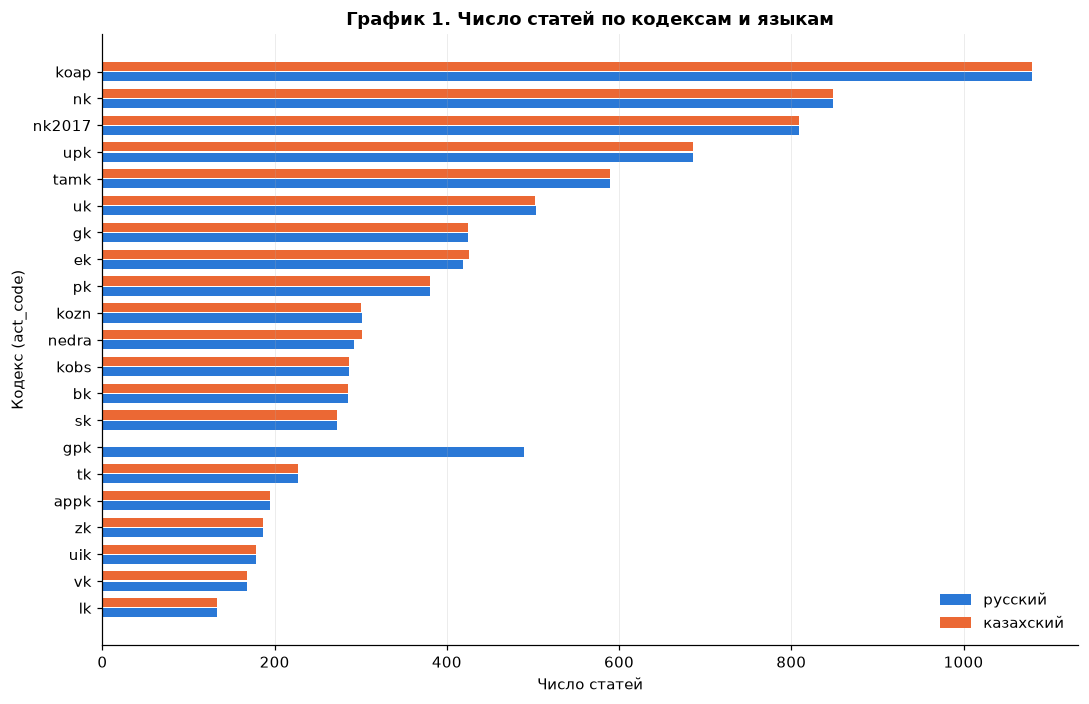

In [19]:
per_act = articles.groupby(["act_code", "lang"], observed=True).size().unstack(fill_value=0)
per_act = per_act.loc[per_act.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(per_act))
height = 0.38
for offset, lang in ((-height / 2, "ru"), (height / 2, "kk")):
    ax.barh(y + offset, per_act[lang], height=height - 0.04, color=LANG_COLORS[lang],
            label={"ru": "русский", "kk": "казахский"}[lang])
ax.set_yticks(y, per_act.index)
ax.set_xlabel("Число статей")
ax.set_ylabel("Кодекс (act_code)")
ax.set_title("График 1. Число статей по кодексам и языкам")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [20]:
coverage = (per_act["kk"] / per_act["ru"]).sort_values()
print(f"Крупнейший кодекс: {per_act.sum(axis=1).idxmax()} ({per_act.sum(axis=1).max():,} статей RU+KK); "
      f"5 крупнейших кодексов дают {per_act.sum(axis=1).nlargest(5).sum() / per_act.values.sum():.0%} статей.")
print("Отношение числа KK-статей к RU (меньше 1 — неполное покрытие):")
print(coverage.round(3).head(5).to_string())

Крупнейший кодекс: koap (2,158 статей RU+KK); 5 крупнейших кодексов дают 47% статей.
Отношение числа KK-статей к RU (меньше 1 — неполное покрытие):
act_code
gpk       0.000
uk        0.996
kozn      0.997
lk        1.000
nk2017    1.000


**Интерпретация.** Корпус сильно несбалансирован по кодексам: несколько крупных кодексов (налоговые,
предпринимательский, КоАП) содержат большую часть статей. Для оценки это значит, что средняя метрика по всем
запросам в основном отражает качество на крупных кодексах — поэтому распределение кодексов проверяется отдельно
при разбиении (§8). По языкам покрытие почти полное: кроме ГПК (только RU), KK-версия существует для
подавляющего большинства статей, поэтому ключевое выравнивание RU↔KK по `article_id` работает (ответ на RQ2 в части
структуры: казахский парсится в тот же скелет, а не в «плоский» текст).

### 6.2 Длина статей и порог нарезки

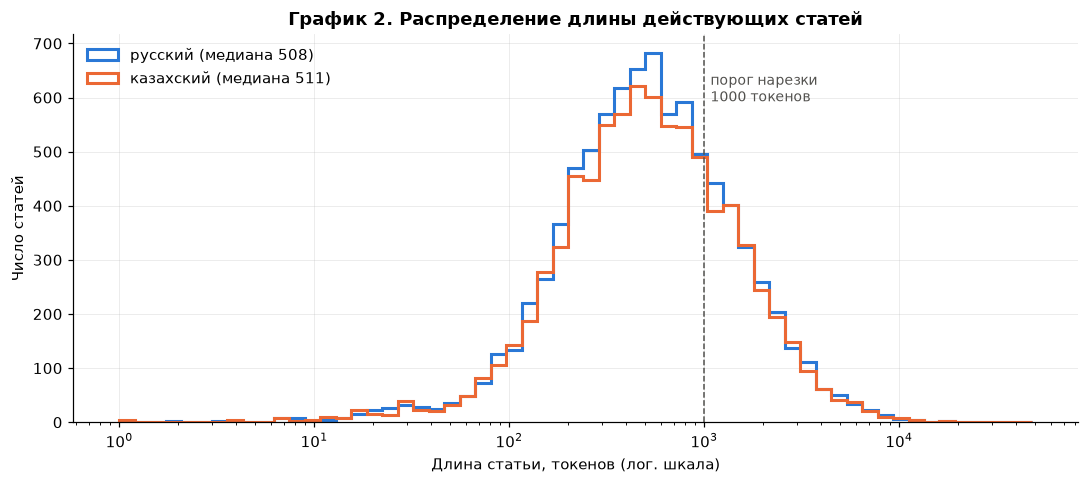

Статей длиннее порога: 25.2%; фрагментов-пунктов в индексе: 70.6%


In [21]:
bins = np.logspace(np.log10(max(articles_text.tokens.min(), 1)), np.log10(articles_text.tokens.max()), 60)
fig, ax = plt.subplots()
for lang in ("ru", "kk"):
    values = articles_text.loc[articles_text.lang == lang, "tokens"]
    ax.hist(values, bins=bins, histtype="step", linewidth=2, color=LANG_COLORS[lang],
            label=f"{'русский' if lang == 'ru' else 'казахский'} (медиана {values.median():.0f})")
ax.axvline(MAX_ARTICLE_TOKENS, color="#52514e", linestyle="--", linewidth=1)
ax.text(MAX_ARTICLE_TOKENS * 1.08, ax.get_ylim()[1] * 0.9, f"порог нарезки\n{MAX_ARTICLE_TOKENS} токенов",
        fontsize=9, color="#52514e", va="top")
ax.set_xscale("log")
ax.set_xlabel("Длина статьи, токенов (лог. шкала)")
ax.set_ylabel("Число статей")
ax.set_title("График 2. Распределение длины действующих статей")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

over = (articles_text.tokens > MAX_ARTICLE_TOKENS).mean()
print(f"Статей длиннее порога: {over:.1%}; фрагментов-пунктов в индексе: {(~chunks.is_whole_article).mean():.1%}")

**Интерпретация.** Распределение длины близко к лог-нормальному с тяжёлым правым хвостом: медианная статья —
около 500 токенов, но есть статьи в десятки тысяч токенов (основные понятия, таблицы ставок). Порог нарезки
превышает примерно четверть статей, и именно они дают большинство фрагментов индекса (фрагменты-пункты).
Это обосновывает правило проекта «статья целиком, пункты — только для больших статей»: три четверти норм
индексируются целиком, а фиксированное окно в N токенов разрезало бы их без нужды. Кривые RU и KK почти совпадают.

### 6.3 RU и KK: один и тот же закон — разные тексты

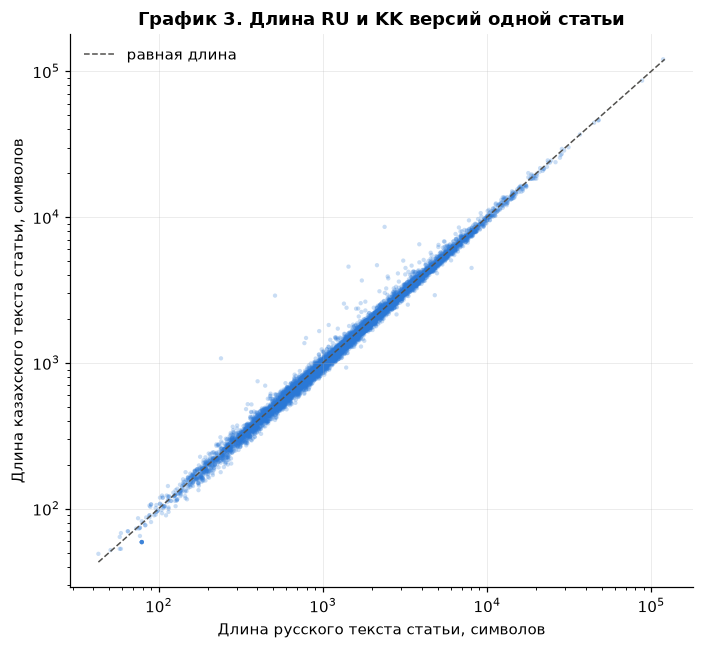

Выровненных статей: 7,995; KK/RU по длине: медиана 0.98, IQR 0.94–1.02; корреляция log-длин: 0.997; статей с отношением вне [0.5, 2]: 6


In [22]:
aligned = articles_text.pivot_table(index="article_id", columns="lang", values="body_chars", observed=True).dropna()
aligned = aligned[(aligned.ru > 0) & (aligned.kk > 0)]
ratio = aligned.kk / aligned.ru

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(aligned.ru, aligned.kk, s=8, alpha=0.25, color=SINGLE_COLOR, edgecolors="none")
limits = [aligned.values.min(), aligned.values.max()]
ax.plot(limits, limits, color="#52514e", linestyle="--", linewidth=1, label="равная длина")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Длина русского текста статьи, символов")
ax.set_ylabel("Длина казахского текста статьи, символов")
ax.set_title("График 3. Длина RU и KK версий одной статьи")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Выровненных статей: {len(aligned):,}; KK/RU по длине: медиана {ratio.median():.2f}, "
      f"IQR {ratio.quantile(.25):.2f}–{ratio.quantile(.75):.2f}; "
      f"корреляция log-длин: {np.corrcoef(np.log(aligned.ru), np.log(aligned.kk))[0, 1]:.3f}; "
      f"статей с отношением вне [0.5, 2]: {((ratio < 0.5) | (ratio > 2)).sum()}")

**Интерпретация.** Точки лежат узкой полосой вдоль диагонали: длины RU и KK версий практически пропорциональны
(корреляция лог-длин ≈ 1, медианное отношение KK/RU ≈ 1 с узким IQR). Это сильное подтверждение корректности
выравнивания по `article_id`: если бы казахский парсер сдвигал нумерацию статей, полоса рассыпалась бы.
Казахский текст в символах не длиннее русского — агглютинация удлиняет слова, но уменьшает их число.
Единичные точки вне полосы [0,5; 2] — кандидаты в ошибки разбора и готовый инструмент контроля качества.

### 6.4 Время: когда вступили в силу текущие редакции статей (RQ3)

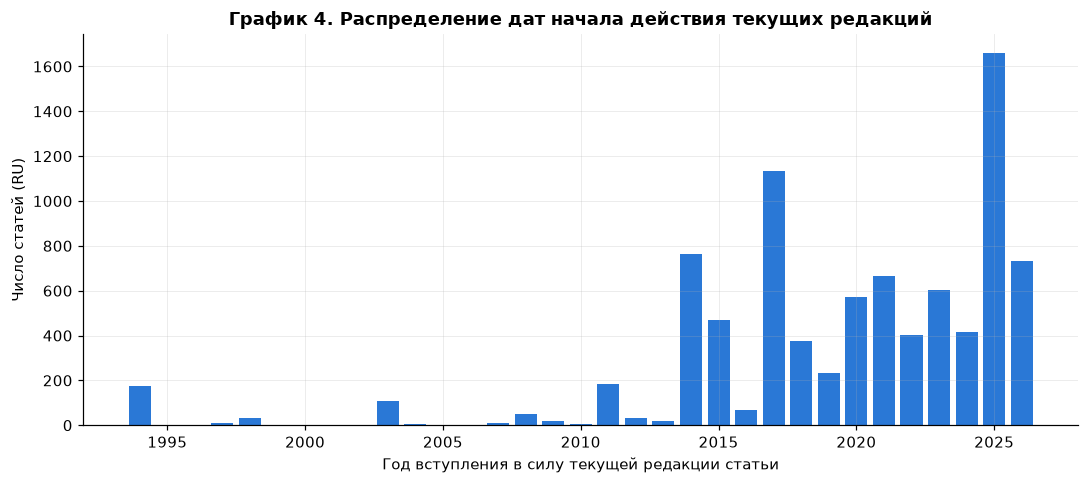

Кодексы, дающие пики: {2025: {'nk': 836, 'koap': 200}, 2017: {'tamk': 446, 'nk2017': 332}, 2014: {'upk': 306, 'koap': 269}}
Статей с известной датой: 17,029 из 17,029; редакция новее даты принятия кодекса: 54%; редакция вступила в силу за последние 3 года: 33%; вступает в силу после даты снимка: 0


In [23]:
dated_articles = articles[articles.valid_from.notna()].copy()
dated_articles["year"] = dated_articles.valid_from.dt.year
adoption = articles.groupby("act_code", observed=True).valid_from.min()
dated_articles["amended_after_adoption"] = dated_articles.valid_from > dated_articles.act_code.map(adoption)
year_counts = dated_articles[dated_articles.lang == "ru"].year.value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(year_counts.index, year_counts.values, width=0.8, color=SINGLE_COLOR)
ax.set_xlabel("Год вступления в силу текущей редакции статьи")
ax.set_ylabel("Число статей (RU)")
ax.set_title("График 4. Распределение дат начала действия текущих редакций")
plt.tight_layout()
plt.show()

recent = (dated_articles.year >= snapshot_day.year - 2).mean()
top_years = year_counts.nlargest(3).index
print("Кодексы, дающие пики:", {int(y): dated_articles[(dated_articles.lang == "ru") & (dated_articles.year == y)]
      .act_code.value_counts().head(2).to_dict() for y in top_years})
print(f"Статей с известной датой: {len(dated_articles):,} из {len(articles):,}; "
      f"редакция новее даты принятия кодекса: {dated_articles.amended_after_adoption.mean():.0%}; "
      f"редакция вступила в силу за последние 3 года: {recent:.0%}; "
      f"вступает в силу после даты снимка: {(dated_articles.valid_from.dt.date > snapshot_day).sum()}")

**Интерпретация (RQ3).** Даты начала действия распределены от середины 1990-х до текущего года с сильной
концентрацией в последние годы; пики соответствуют принятию новых кодексов и массовым поправкам (кодексы,
дающие пики, напечатаны выше). При этом больше половины статей имеют редакцию, изменённую уже после принятия кодекса,
около трети — изменённую за последние три года. Значит, вопрос «какая норма действовала на дату события» реально
имеет разные ответы для разных дат — дата «по состоянию на» должна быть жёстким фильтром, а не сигналом ранжирования.
Одновременно график показывает ограничение: снимок хранит только *текущие* редакции, поэтому для дат раньше
последнего изменения система вынуждена отвечать «текста на эту дату нет».

### 6.5 Состав пар и длина запросов по типам

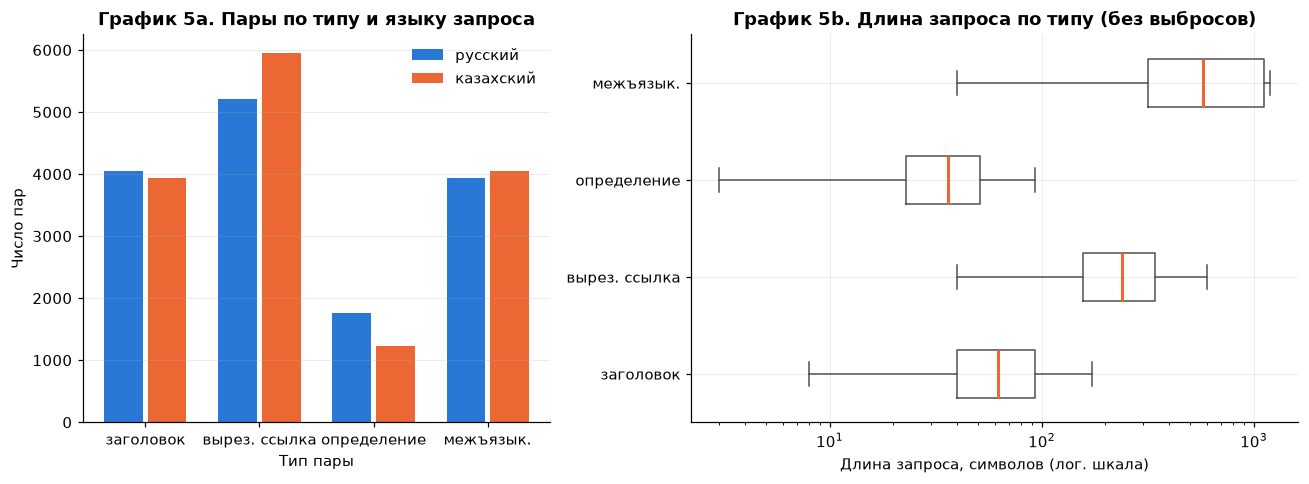

,count,50%,mean,max
kind,,,,
definition,2990.0,36.0,40.0,140.0
heading,8000.0,62.0,75.0,523.0
xlang,8000.0,576.0,663.0,1200.0
xref,11167.0,240.0,259.0,600.0


In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
kind_lang = pairs.groupby(["kind", "lang"]).size().unstack(fill_value=0).reindex(KIND_ORDER)
x = np.arange(len(KIND_ORDER))
width = 0.38
for offset, lang in ((-width / 2, "ru"), (width / 2, "kk")):
    ax1.bar(x + offset, kind_lang[lang], width=width - 0.04, color=LANG_COLORS[lang],
            label={"ru": "русский", "kk": "казахский"}[lang])
ax1.set_xticks(x, [KIND_LABELS[k] for k in KIND_ORDER])
ax1.set_xlabel("Тип пары")
ax1.set_ylabel("Число пар")
ax1.set_title("График 5a. Пары по типу и языку запроса")
ax1.legend()
ax1.grid(axis="x", visible=False)

data = [pairs.loc[pairs.kind == k, "query_chars"] for k in KIND_ORDER]
ax2.boxplot(data, orientation="horizontal", showfliers=False, widths=0.5,
            medianprops={"color": "#eb6834", "linewidth": 2}, boxprops={"color": "#52514e"},
            whiskerprops={"color": "#52514e"}, capprops={"color": "#52514e"})
ax2.set_yticks(range(1, len(KIND_ORDER) + 1), [KIND_LABELS[k] for k in KIND_ORDER])
ax2.set_xscale("log")
ax2.set_xlabel("Длина запроса, символов (лог. шкала)")
ax2.set_title("График 5b. Длина запроса по типу (без выбросов)")
plt.tight_layout()
plt.show()
display(pairs.groupby("kind").query_chars.describe()[["count", "50%", "mean", "max"]].round(0))

**Интерпретация.** Типы пар сильно различаются по форме: заголовки и определения — короткие (несколько слов,
как запрос в поисковой строке), xref — одно предложение закона, xlang — целый фрагмент текста. Поэтому единая
средняя метрика бессмысленна: результаты baseline ниже приводятся отдельно по типам. По языкам пары
распределены почти поровну — следствие полного двуязычного покрытия (график 1).

### 6.6 Взаимосвязь признака и target: лексическое перекрытие запроса и целевой статьи

Ключевой вопрос для выбора метода поиска — сколько слов запроса буквально встречается в правильной статье.
Считаем долю слов запроса (длиной ≥ 4 символов), присутствующих в тексте целевого фрагмента.

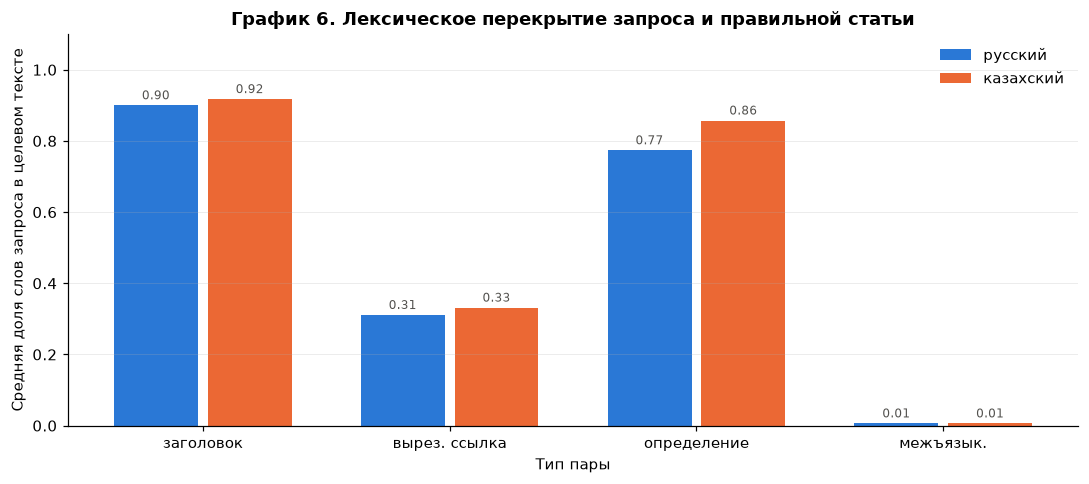

Медианы:


lang,kk,ru
kind,,
heading,1.0,1.00
xref,0.3,0.28
definition,1.0,0.80
xlang,0.0,0.00


In [25]:
WORD_RE = re.compile(r"\w{4,}", re.UNICODE)
chunk_text = chunks.set_index("chunk_id")["display_text"]


def query_coverage(query: str, target: str) -> float:
    words = set(WORD_RE.findall(query.lower()))
    if not words:
        return np.nan
    target_words = set(WORD_RE.findall(target.lower()))
    return len(words & target_words) / len(words)


pairs["coverage"] = [query_coverage(q, chunk_text.get(t, "")) for q, t in zip(pairs["query"], pairs["target_chunk"])]

mean_coverage = pairs.pivot_table(index="kind", columns="lang", values="coverage", aggfunc="mean").reindex(KIND_ORDER)
fig, ax = plt.subplots()
positions = np.arange(len(KIND_ORDER))
width = 0.38
for offset, lang in ((-width / 2, "ru"), (width / 2, "kk")):
    bars = ax.bar(positions + offset, mean_coverage[lang], width=width - 0.04, color=LANG_COLORS[lang],
                  label={"ru": "русский", "kk": "казахский"}[lang])
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in mean_coverage[lang]], fontsize=8, padding=2, color="#52514e")
ax.set_xticks(positions, [KIND_LABELS[k] for k in KIND_ORDER])
ax.set_ylim(0, 1.1)
ax.set_xlabel("Тип пары")
ax.set_ylabel("Средняя доля слов запроса в целевом тексте")
ax.set_title("График 6. Лексическое перекрытие запроса и правильной статьи")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print("Медианы:")
display(pairs.pivot_table(index="kind", columns="lang", values="coverage", aggfunc="median").reindex(KIND_ORDER).round(2))

**Интерпретация.** Перекрытие — сильнейший предиктор того, сможет ли лексический поиск найти статью.
У заголовков и определений оно близко к 100 % (запрос — это буквально кусок статьи), у xref-предложений оно
частичное (около трети слов: предложение описывает ту же тему другими словами), а у межъязыковых пар равно нулю:
русский и казахский тексты одной нормы не делят слов. Между языками при одинаковом типе пары перекрытие почти
одинаково — то есть на запросах, *добытых из самого корпуса*, казахская морфология лексическому поиску не мешает
(запрос и статья написаны в одних и тех же словоформах). Это прогноз для RQ1/H1 и RQ2/H2, проверяемый в §9.

### 6.7 Граф цитирования: какие статьи становятся target

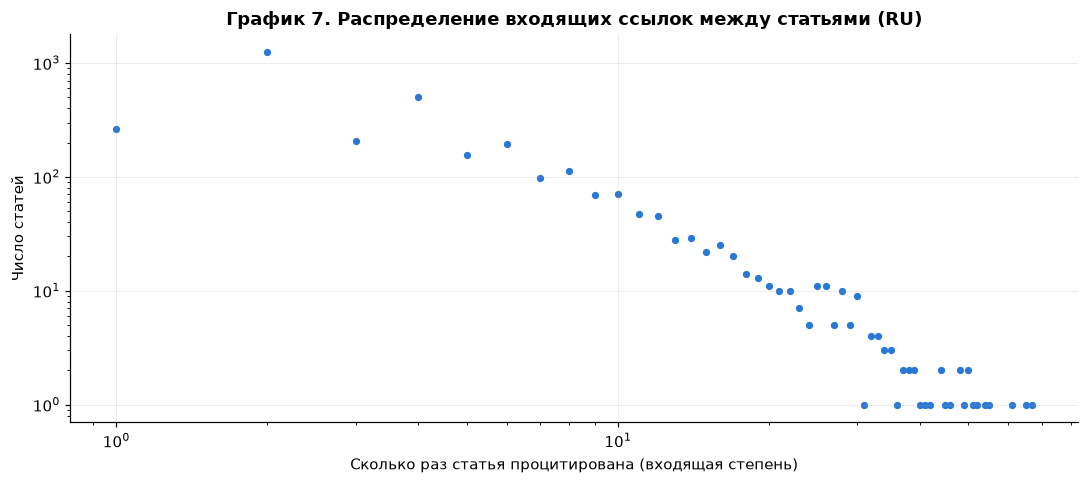

Ссылок найдено: 31,998; указывают на существующую статью корпуса: 98.7%; межкодексных среди разрешённых: 6.1%
Хотя бы раз процитированы 38% RU-статей; топ-1 % статей получает 8% всех ссылок.
Самые цитируемые статьи:
dst
nk2017/st48    67
tamk/st184     65
tamk/st137     61
tamk/st192     55
tamk/st141     54


In [26]:
ref_rows = []
for root, doc in trees:
    for node in root.walk():
        if node.kind not in (NodeKind.ARTICLE, NodeKind.POINT, NodeKind.NOTE):
            continue
        text = node.texts.get(doc.lang)
        if text is None or not text.body:
            continue
        for ref in R.extract_refs(node.id, doc.act_code, text.body, doc.lang):
            ref_rows.append({"lang": doc.lang.value, "src_act": doc.act_code, "dst": ref.dst_node_id,
                             "dst_act": ref.dst_act_code})
refs_df = pd.DataFrame(ref_rows)
known_articles = set(articles.article_id)
resolved = refs_df.dst.map(lambda n: isinstance(n, str) and n.split("/p")[0] in known_articles)
in_degree = refs_df[resolved & (refs_df.lang == "ru")].dst.map(lambda n: n.split("/p")[0]).value_counts()

fig, ax = plt.subplots()
degree_freq = in_degree.value_counts().sort_index()
ax.scatter(degree_freq.index, degree_freq.values, s=14, color=SINGLE_COLOR)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Сколько раз статья процитирована (входящая степень)")
ax.set_ylabel("Число статей")
ax.set_title("График 7. Распределение входящих ссылок между статьями (RU)")
plt.tight_layout()
plt.show()

cited_share = len(in_degree) / (articles.lang == "ru").sum()
print(f"Ссылок найдено: {len(refs_df):,}; указывают на существующую статью корпуса: {resolved.mean():.1%}; "
      f"межкодексных среди разрешённых: {(refs_df[resolved].src_act != refs_df[resolved].dst_act).mean():.1%}")
print(f"Хотя бы раз процитированы {cited_share:.0%} RU-статей; топ-1 % статей получает "
      f"{in_degree.nlargest(max(1, len(in_degree) // 100)).sum() / in_degree.sum():.0%} всех ссылок.")
print("Самые цитируемые статьи:")
print(in_degree.head(5).to_string())

**Интерпретация.** После пика на 2 ссылках распределение входящих ссылок убывает почти по прямой на лог-лог
шкале: большинство процитированных статей упоминаются 1–4 раза, единицы — несколько десятков раз; около 60 % статей не цитируются вовсе.
Для датасета это значит, что xref-пары покрывают лишь часть статей и неравномерно, поэтому разбиение по статьям
обязательно: иначе модель могла бы запомнить частые target'ы. Почти все извлечённые ссылки указывают на
существующую статью корпуса, а межкодексные ссылки составляют малую долю — ссылки на законы вне 21 кодекса
экстрактор просто не распознаёт, поэтому эта цифра описывает точность ссылок, а не полноту графа.

### 6.8 Сводка аналитических наблюдений

In [27]:
summary_obs = [
    f"Корпус: {articles.article_id.nunique():,} уникальных статей, {len(chunks):,} фрагментов, "
    f"5 крупнейших кодексов = {per_act.sum(axis=1).nlargest(5).sum() / per_act.values.sum():.0%} статей — сильный дисбаланс по кодексам.",
    f"Выравнивание RU↔KK почти полное: {len(aligned):,} статей с обеими версиями; отношение длин KK/RU — медиана {ratio.median():.2f}, корреляция лог-длин {np.corrcoef(np.log(aligned.ru), np.log(aligned.kk))[0, 1]:.3f}.",
    f"{over:.1%} статей превышают порог нарезки и дают {(~chunks.is_whole_article).mean():.0%} фрагментов индекса.",
    f"{dated_articles.amended_after_adoption.mean():.0%} статей имеют редакцию новее даты принятия кодекса — дата «по состоянию на» существенна (RQ3).",
    "Лексическое перекрытие запроса с правильной статьёй (медиана): " + ", ".join(
        f"{KIND_LABELS[k]} {pairs.loc[pairs.kind == k, 'coverage'].median():.2f}" for k in KIND_ORDER) + ".",
    f"Перекрытие KK-запросов с целью — медиана {pairs.loc[pairs.lang == 'kk', 'coverage'].median():.2f} "
    f"против {pairs.loc[pairs.lang == 'ru', 'coverage'].median():.2f} у RU: на корпусных запросах языки лексически равны (RQ2).",
    f"Цитируется хотя бы раз {cited_share:.0%} RU-статей; {resolved.mean():.0%} извлечённых ссылок указывают на существующую статью.",
    f"{len(ambiguous_queries):,} запросов указывали на несколько статей — устранено при очистке.",
]
for i, line in enumerate(summary_obs, 1):
    print(f"{i}. {line}")

1. Корпус: 8,771 уникальных статей, 43,857 фрагментов, 5 крупнейших кодексов = 47% статей — сильный дисбаланс по кодексам.
2. Выравнивание RU↔KK почти полное: 7,995 статей с обеими версиями; отношение длин KK/RU — медиана 0.98, корреляция лог-длин 0.997.
3. 25.2% статей превышают порог нарезки и дают 71% фрагментов индекса.
4. 54% статей имеют редакцию новее даты принятия кодекса — дата «по состоянию на» существенна (RQ3).
5. Лексическое перекрытие запроса с правильной статьёй (медиана): заголовок 1.00, вырез. ссылка 0.29, определение 0.89, межъязык. 0.00.
6. Перекрытие KK-запросов с целью — медиана 0.33 против 0.33 у RU: на корпусных запросах языки лексически равны (RQ2).
7. Цитируется хотя бы раз 38% RU-статей; 99% извлечённых ссылок указывают на существующую статью.
8. 2,347 запросов указывали на несколько статей — устранено при очистке.


## 7. Признаки и target

**Постановка.** Задача — ранжирование (информационный поиск), а не классификация с фиксированным набором меток:

* **X (признаки)** — текст запроса `query` и его язык `lang`. Из текста baseline извлекает признаки TF-IDF
  (символьные n-граммы); плотная модель — эмбеддинг.
* **y (target)** — пара `(target_article, pos_lang)`: статья и язык, в которых находится ответ. Предсказание
  засчитывается, если в топ-k выдачи есть любой фрагмент этой статьи на этом языке (то же определение использует
  `lawrag.train.evaluate`).

**Почему именно этот target.** Статья — минимальная единица, на которую юрист ссылается («ст. 278 КоАП»), и та
единица, которую верифицирует проверка цитат проекта. Target на уровне фрагмента был бы слишком строгим
(пункт 2 вместо пункта 3 той же статьи — всё равно правильная норма), а на уровне кодекса — бесполезным.
Язык входит в target, потому что для межъязыковой пары RU-текст статьи тривиально находит *русскую* версию той же
статьи; без языка в target метрика была бы завышена до ~100 %.

**Влияние ключевых признаков на target:**

| Признак | Потенциальное влияние |
|---|---|
| слова/n-граммы запроса | основной сигнал; сила зависит от лексического перекрытия (график 6) |
| `lang` запроса | определяет морфологию; KK-запросы хуже находятся лексически (H2) |
| длина запроса | короткие запросы (заголовки) точны, но многозначны; длинные (xlang) информативны, но шумны |
| упоминание кодекса в запросе | сужает пространство поиска до одного кодекса (в xref-предложениях название кодекса часто остаётся) |
| `kind` | **не признак**: тип пары неизвестен в момент реального запроса; используется только для анализа и стратификации |

### Проверка риска утечки данных (data leakage)

In [28]:
leak_checks = pd.DataFrame({"кол-во": [
    int(sum(bool(re.search(rf"(?<![\d-]){re.escape(n)}(?![\d-])", q))
            for q, n in zip(pairs.loc[pairs.kind == "xref", "query"],
                            pairs.loc[pairs.kind == "xref", "target_article"].str.split("/st").str[1]))),
    int(pairs.groupby("query_norm").target_article.nunique().gt(1).sum()),
    int(((pairs.kind == "xlang") & (pairs.lang == pairs.pos_lang)).sum()),
]}, index=["xref-запрос содержит номер целевой статьи", "запрос с несколькими target после очистки",
           "xlang-пара с одинаковым языком запроса и цели"])
leak_checks

,кол-во
xref-запрос содержит номер целевой статьи,0
запрос с несколькими target после очистки,0
xlang-пара с одинаковым языком запроса и цели,0


Источники утечки и как они закрыты:

1. **Номер статьи в запросе** (xref) — номер вырезается майнером; остаточные случаи удалены в §5.3, после очистки — 0.
2. **Одна статья в train и test.** Для одной статьи есть пары разных типов (заголовок, xref, xlang в обе стороны,
   определение). При случайном разбиении *по парам* модель видела бы статью в обучении, и тест измерял бы
   запоминание. Поэтому разбиение — **по статьям** (§8), причём `article_id` общий для RU и KK, так что обе языковые
   версии статьи попадают в одну выборку.
3. **Признак, вычисленный по target:** `kind`, `target_chunk`, `coverage` строятся с использованием ответа и
   в признаки не входят.
4. **Утечка через обучение векторизатора.** TF-IDF обучается только на текстах корпуса (индекс поиска), а не на
   запросах; корпус статей в реальной системе известен заранее, поэтому это не утечка, а штатный режим работы
   поисковика.
5. **Время.** Даты действия — свойство корпуса и фильтр при поиске; как признак ранжирования они не используются.

## 8. Разбиение train / validation / test

In [29]:
print("Статей-источников пар по типам:", pairs.groupby("kind").target_article.nunique().to_dict())

folds = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_of = np.empty(len(pairs), dtype=int)
for fold, (_, idx) in enumerate(folds.split(pairs, y=pairs["kind"], groups=pairs["target_article"])):
    fold_of[idx] = fold
pairs["split"] = np.select([fold_of == TEST_FOLD, fold_of == VAL_FOLD], ["test", "validation"], "train")
splits = {name: pairs[pairs.split == name].reset_index(drop=True) for name in ("train", "validation", "test")}

split_table = pd.DataFrame({
    "пар": pairs.split.value_counts(),
    "статей": pairs.groupby("split").target_article.nunique(),
}).loc[["train", "validation", "test"]]
split_table["% пар"] = (split_table["пар"] / len(pairs) * 100).round(1)
display(split_table)

overlap = {(a, b): len(set(splits[a].target_article) & set(splits[b].target_article))
           for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))}
print("Пересечение статей между выборками:", overlap)

Статей-источников пар по типам: {'definition': 16, 'heading': 5789, 'xlang': 3963, 'xref': 2519}


,пар,статей,% пар
split,,,
train,23842,6005,79.1
validation,3069,740,10.2
test,3246,740,10.8


Пересечение статей между выборками: {('train', 'validation'): 0, ('train', 'test'): 0, ('validation', 'test'): 0}


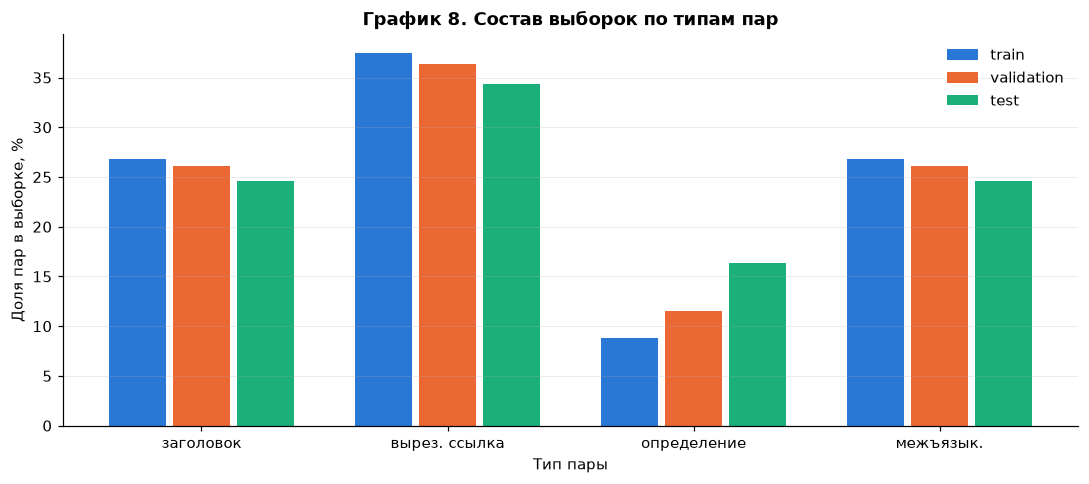

Макс. отклонение доли validation/test от train, п.п.: {'тип пары': 7.49, 'язык': 0.97, 'кодекс': 16.59}


In [30]:
def composition(column: str) -> pd.DataFrame:
    return pd.crosstab(pairs[column], pairs["split"], normalize="columns")[["train", "validation", "test"]] * 100


kind_comp = composition("kind").reindex(KIND_ORDER)
lang_comp = composition("lang")
act_comp = pd.crosstab(pairs["target_article"].str.split("/").str[0], pairs["split"], normalize="columns") * 100
max_dev = {name: float((comp[["validation", "test"]].sub(comp["train"], axis=0)).abs().max().max())
           for name, comp in (("тип пары", kind_comp), ("язык", lang_comp), ("кодекс", act_comp))}

fig, ax = plt.subplots()
x = np.arange(len(KIND_ORDER))
width = 0.26
for i, (name, color) in enumerate((("train", "#2a78d6"), ("validation", "#eb6834"), ("test", "#1baf7a"))):
    ax.bar(x + (i - 1) * width, kind_comp[name], width=width - 0.03, color=color, label=name)
ax.set_xticks(x, [KIND_LABELS[k] for k in KIND_ORDER])
ax.set_xlabel("Тип пары")
ax.set_ylabel("Доля пар в выборке, %")
ax.set_title("График 8. Состав выборок по типам пар")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print("Макс. отклонение доли validation/test от train, п.п.:", {k: round(v, 2) for k, v in max_dev.items()})

**Обоснование разбиения.**

* **Пропорции 80/10/10.** Обучающих пар ~30 тыс., поэтому 10 % на validation и test дают по ~3 тыс. запросов —
  достаточно для оценки recall с погрешностью около ±1–2 п.п. по каждому типу пар, и при этом ~80 % данных остаются
  для контрастивного дообучения эмбеддера.
* **Группировка по статье** (а не по паре) — главное требование против утечки (§7): пересечение статей между
  выборками равно нулю.
* **Стратификация.** Классической стратификации по метке нет (target — тысячи статей), но есть страта, от которой
  зависит метрика, — тип пары. Определения сосредоточены в немногих статьях «Основные понятия» (одна на кодекс,
  сотни пар на статью), и простое случайное разбиение по статьям в первой версии этого ноутбука оставило test
  вовсе без определений. Поэтому используется `StratifiedGroupKFold` (группа — статья, страта — тип пары,
  фиксированный `SEED`): он балансирует типы, не нарушая группировку. Остаточное отклонение долей приведено под
  графиком 8: по языку — около 1 п.п., по кодексу — больше, потому что статьи с сотнями пар (определения крупных
  кодексов) неделимы как группы. Это осознанная цена отсутствия утечки; метрики поэтому приводятся по типам и языкам.
* **Время.** Данные — один снимок закона, а не временной ряд: запросы не упорядочены во времени, и будущая
  информация не может «просочиться» в прошлое через пары. Поэтому случайное (хэш-) разбиение допустимо; временная
  корректность обеспечивается фильтром по дате в поиске, а не порядком выборок.

## 9. Baseline: лексический поиск TF-IDF

Индекс — все фрагменты корпуса (оба языка). Запрос и фрагменты векторизуются TF-IDF, ранжирование по косинусу,
метрики: recall@1, recall@10, MRR@10. На **validation** выбирается конфигурация векторизатора
(словные униграммы+биграммы против символьных n-грамм), на **test** — однократная финальная оценка.
Train baseline не использует (у TF-IDF нет обучаемых параметров кроме словаря, построенного по корпусу) —
он предназначен для дообучения эмбеддера на следующем этапе.

In [31]:
chunk_keys = list(zip(chunks["article_id"].astype(str), chunks["lang"].astype(str)))
chunk_key_codes = pd.Series(range(len(set(chunk_keys))), index=pd.Index(sorted(set(chunk_keys))))
chunk_key_ids = np.array([chunk_key_codes[k] for k in chunk_keys])

VECTORIZERS = {
    "word 1-2": dict(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=400_000, sublinear_tf=True),
    "char_wb 3-5": dict(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=400_000, sublinear_tf=True),
}


def rank_targets(vectorizer, doc_matrix, queries: pd.DataFrame) -> np.ndarray:
    target_ids = np.array([chunk_key_codes.get((a, l), -1)
                           for a, l in zip(queries["target_article"], queries["pos_lang"])])
    ranks = np.zeros(len(queries), dtype=int)
    for start in range(0, len(queries), QUERY_BATCH):
        q = vectorizer.transform(queries["query"].iloc[start:start + QUERY_BATCH])
        scores = (q @ doc_matrix.T).toarray()
        top = np.argpartition(-scores, TOP_K, axis=1)[:, :TOP_K]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
        top_keys = chunk_key_ids[top]
        for i, row in enumerate(top_keys):
            hit = np.flatnonzero(row == target_ids[start + i])
            ranks[start + i] = hit[0] + 1 if hit.size else 0
    return ranks


def metrics(ranks: np.ndarray) -> dict:
    if len(ranks) == 0:
        return {"n": 0, "recall@1": np.nan, "recall@10": np.nan, "MRR@10": np.nan}
    hit = ranks > 0
    return {"n": len(ranks), "recall@1": np.mean(ranks == 1), "recall@10": np.mean(hit),
            "MRR@10": np.mean(np.where(hit, 1 / np.maximum(ranks, 1), 0))}


def evaluate(ranks: np.ndarray, queries: pd.DataFrame) -> pd.DataFrame:
    rows = {"все": metrics(ranks)}
    for kind in KIND_ORDER:
        rows[KIND_LABELS[kind]] = metrics(ranks[(queries.kind == kind).values])
    for lang in ("ru", "kk"):
        rows[f"язык {lang}"] = metrics(ranks[(queries.lang == lang).values])
    return pd.DataFrame(rows).T.round(3).astype({"n": int})


fitted = {}
val_results = {}
for name, params in VECTORIZERS.items():
    started = time.time()
    vectorizer = TfidfVectorizer(lowercase=True, dtype=np.float32, **params)
    doc_matrix = vectorizer.fit_transform(chunks["display_text"])
    fitted[name] = (vectorizer, doc_matrix)
    val_results[name] = evaluate(rank_targets(vectorizer, doc_matrix, splits["validation"]), splits["validation"])
    print(f"{name}: словарь {len(vectorizer.vocabulary_):,}, время {time.time() - started:.0f} с, "
          f"val MRR@10 = {val_results[name].loc['все', 'MRR@10']:.3f}")

pd.concat(val_results, axis=1)

word 1-2: словарь 400,000, время 8 с, val MRR@10 = 0.252


char_wb 3-5: словарь 169,496, время 39 с, val MRR@10 = 0.231


word 1-2                           char_wb 3-5                          
                     n recall@1 recall@10 MRR@10           n recall@1 recall@10 MRR@10
все               3069    0.187     0.403  0.252        3069    0.166     0.382  0.231
заголовок          800    0.675     0.948  0.771         800    0.578     0.894  0.682
вырез. ссылка     1116    0.027     0.358  0.121        1116    0.042     0.380  0.141
определение        353    0.014     0.215  0.061         353    0.000     0.082  0.018
межъязык.          800    0.000     0.004  0.001         800    0.000     0.004  0.001
язык ru           1530    0.186     0.406  0.253        1530    0.169     0.388  0.236
язык kk           1539    0.189     0.400  0.252        1539    0.162     0.375  0.226

In [32]:
best_name = max(val_results, key=lambda n: val_results[n].loc["все", "MRR@10"])
vectorizer, doc_matrix = fitted[best_name]
test_ranks = rank_targets(vectorizer, doc_matrix, splits["test"])
test_results = evaluate(test_ranks, splits["test"])
print(f"Выбрана конфигурация по validation MRR@10: {best_name}. Итоговая оценка на test:")
test_results

Выбрана конфигурация по validation MRR@10: word 1-2. Итоговая оценка на test:


,n,recall@1,recall@10,MRR@10
все,3246,0.173,0.418,0.242
заголовок,800,0.654,0.929,0.750
вырез. ссылка,1116,0.024,0.400,0.127
определение,530,0.023,0.298,0.082
межъязык.,800,0.000,0.014,0.003
язык ru,1583,0.172,0.414,0.241
язык kk,1663,0.174,0.422,0.244


In [33]:
by_kind_lang = pd.DataFrame({(KIND_LABELS[k], lang): metrics(test_ranks[((splits["test"].kind == k)
                                                                       & (splits["test"].lang == lang)).values])
                             for k in KIND_ORDER for lang in ("ru", "kk")}).T
by_kind_lang["n"] = by_kind_lang["n"].astype(int)
print("Test, разбивка тип × язык:")
by_kind_lang.round(3)

Test, разбивка тип × язык:


n  recall@1  recall@10  MRR@10
заголовок     ru  399     0.622      0.915   0.720
              kk  401     0.686      0.943   0.779
вырез. ссылка ru  533     0.028      0.388   0.127
              kk  583     0.021      0.410   0.126
определение   ru  265     0.038      0.291   0.091
              kk  265     0.008      0.306   0.072
межъязык.     ru  386     0.000      0.018   0.004
              kk  414     0.000      0.010   0.003

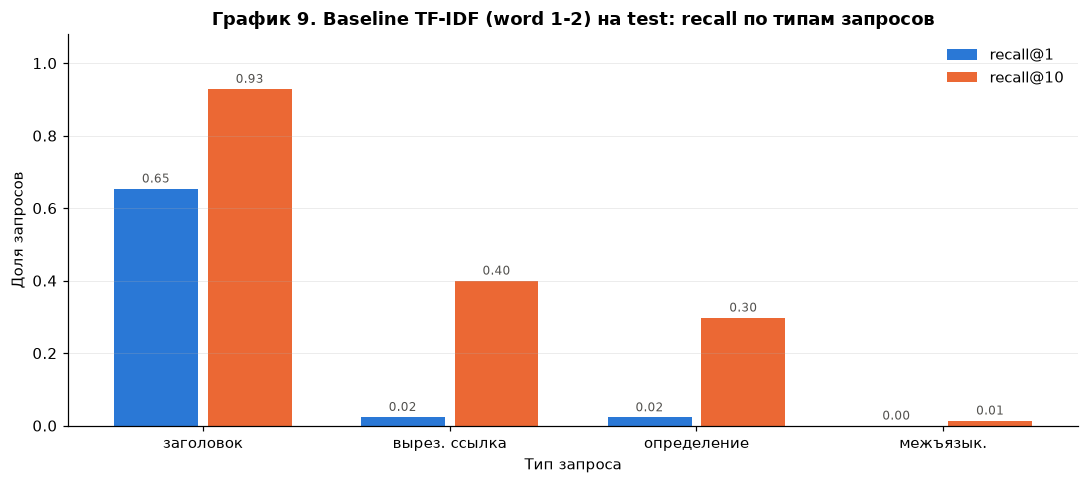

In [34]:
plot_rows = [KIND_LABELS[k] for k in KIND_ORDER]
fig, ax = plt.subplots()
x = np.arange(len(plot_rows))
width = 0.38
for offset, (metric, color) in zip((-width / 2, width / 2), (("recall@1", "#2a78d6"), ("recall@10", "#eb6834"))):
    values = test_results.loc[plot_rows, metric]
    bars = ax.bar(x + offset, values, width=width - 0.04, color=color, label=metric)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], fontsize=8, padding=2, color="#52514e")
ax.set_xticks(x, plot_rows)
ax.set_ylim(0, 1.08)
ax.set_xlabel("Тип запроса")
ax.set_ylabel("Доля запросов")
ax.set_title(f"График 9. Baseline TF-IDF ({best_name}) на test: recall по типам запросов")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 9.1 Научная интерпретация

Результаты сопоставляются с исследовательскими вопросами (точные значения — в таблицах выше и в сводке ниже).

* **RQ1 / H1.** H1 подтверждается. Лексический baseline хорошо работает только там, где запрос — буквальный
  уникальный фрагмент статьи (заголовки: recall@10 > 0,9). На xref-запросах — ближайших к реальным вопросам —
  правильная статья попадает в топ-10 лишь в ~40 % случаев, а на первое место почти никогда: вероятная причина
  (не проверена отдельно) — само цитирующее предложение тоже лежит в индексе, и его статья-источник побеждает
  статью-адресата. Определения, несмотря на высокое перекрытие, находятся плохо: термин («налоговый период»)
  встречается в десятках статей, и TF-IDF не отличает *определяющую* статью от использующих. На межъязыковых
  запросах TF-IDF не работает вовсе — у RU- и KK-текста нет общих слов (график 6). Именно в этих двух типах лежит пространство для доменно
  адаптированного плотного эмбеддера (Задача 3 проекта); общий recall «по всем типам» маскирует эту слабость.
* **RQ2 / H2.** Казахская часть корпуса структурно полноценна (выравнивание RU↔KK почти полное, длины
  пропорциональны), а на корпусных запросах лексически находима так же, как русская: разница recall/MRR между
  языками — в пределах статистического шума. **H2 в этой постановке не подтверждается.** Объяснение — в природе
  запросов: заголовок и предложение-ссылка написаны в тех же словоформах, что и статья, поэтому отсутствие
  казахского стеммера не проявляется. На реальных вопросах пользователей (другие падежные формы, разговорная лексика)
  эффект ожидается, и проверить его можно только на ручном наборе вопросов (Задача 5) — это главный вывод для
  следующего этапа: синтетические пары не способны измерить морфологическую проблему казахского.
* **RQ3 / H3.** Большинство статей имеют редакцию новее даты принятия кодекса, часть норм вступает в силу после
  даты снимка — фильтр «по состоянию на дату» необходим во всех ветках поиска.
* **Что baseline значит для проекта.** Он задаёт нижнюю границу: любая более сложная модель (плотный поиск,
  гибрид RRF, переранжирование) должна превзойти его *именно на xref и межъязыковых запросах* — улучшение только
  на заголовках ничего не говорит о полезности для реального пользователя.

In [35]:
def fmt(row: str, metric: str) -> str:
    return f"{test_results.loc[row, metric]:.2f}"


print("Ключевые числа для отчёта (test):")
for row in ["все", *plot_rows, "язык ru", "язык kk"]:
    print(f"  {row:>14}: recall@1 {fmt(row, 'recall@1')}, recall@10 {fmt(row, 'recall@10')}, "
          f"MRR@10 {fmt(row, 'MRR@10')}, n={test_results.loc[row, 'n']}")
h1 = (test_results.loc["заголовок", "recall@10"] > 0.8 and test_results.loc["вырез. ссылка", "recall@10"] < 0.5
      and test_results.loc["межъязык.", "recall@10"] < 0.1)
h2 = test_results.loc["язык kk", "MRR@10"] < test_results.loc["язык ru", "MRR@10"]
h3 = dated_articles.amended_after_adoption.mean() > 0.5
print(f"H1 подтверждена: {h1}; H2 подтверждена: {h2}; H3 подтверждена: {h3}")

Ключевые числа для отчёта (test):
             все: recall@1 0.17, recall@10 0.42, MRR@10 0.24, n=3246
       заголовок: recall@1 0.65, recall@10 0.93, MRR@10 0.75, n=800
   вырез. ссылка: recall@1 0.02, recall@10 0.40, MRR@10 0.13, n=1116
     определение: recall@1 0.02, recall@10 0.30, MRR@10 0.08, n=530
       межъязык.: recall@1 0.00, recall@10 0.01, MRR@10 0.00, n=800
         язык ru: recall@1 0.17, recall@10 0.41, MRR@10 0.24, n=1583
         язык kk: recall@1 0.17, recall@10 0.42, MRR@10 0.24, n=1663
H1 подтверждена: True; H2 подтверждена: False; H3 подтверждена: True


## 10. Ограничения и следующие шаги

* **Синтетические запросы.** Пары добыты из самого корпуса; реальные вопросы пользователей длиннее и разговорнее.
  Набор, написанный вручную и выверенный юристом, — открытый пункт проекта (Задача 5).
* **Только текущие редакции.** Снимок не содержит исторических текстов; анализ дат описывает начало действия
  текущей редакции, а не полную историю изменений.
* **Оценка длины в токенах** приблизительная (≈2,5 символа на токен); точное число зависит от токенизатора модели.
* **Baseline — только лексическая ветка.** Не включены плотный поиск, ветка прямых ссылок, RRF и порог
  релевантности; их сравнение с этим baseline — следующий этап (дообучение эмбеддера на train-части этих пар).